# IELTS Writing Task 2 Scoring Chatbot

## Phần 1. Khởi tạo môi trường và đọc dữ liệu

In [25]:
#Import thư viện và đọc dữ liệu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (9833, 4)
Test: (491, 4)


In [26]:
#Cấu trúc dữ liệu
print("Các cột trong train:")
print(train.columns.tolist())

print("\nCác cột trong test:")
print(test.columns.tolist())

print("\nThông tin train:")
train.info()

print("\n5 dòng đầu của train:")
display(train.head())

print("\n5 dòng đầu của test:")
display(test.head())

Các cột trong train:
['prompt', 'essay', 'evaluation', 'band']

Các cột trong test:
['prompt', 'essay', 'evaluation', 'band']

Thông tin train:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9833 entries, 0 to 9832
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   prompt      9833 non-null   object
 1   essay       9833 non-null   object
 2   evaluation  9833 non-null   object
 3   band        9833 non-null   object
dtypes: object(4)
memory usage: 307.4+ KB

5 dòng đầu của train:


,prompt,essay,evaluation,band
0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,**Task Achievement: [7]**\nThe essay effective...,7.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,**Task Achievement:** 5.0\n- The candidate has...,5.0\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,## Task Achievement:\n- The candidate has effe...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,## Task Achievement:\n- The candidate has adeq...,5.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,**Task Achievement:**\n\nThe essay adequately ...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r



5 dòng đầu của test:


,prompt,essay,evaluation,band
0,Interview form the basic selection criteria fo...,To agree or disagree with the statement that i...,**Task Achievement (6.5)**\n- The essay effect...,6.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
1,The increase in the production of consumer con...,It is true that the rise in consumer productio...,**Task Achievement:**\n- The essay adequately ...,8\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
2,The increase in the production of consumer goo...,It is widely argued that the growth of the num...,**Task Achievement:**\n\nThe essay effectively...,8.5\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
3,The increase in the production of consumer goo...,The production of new items and objects have b...,## Task Achievement:\n- The candidate has part...,<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
4,The increase in the production of consumer goo...,"In recent years, an increase in the manufactur...",**Task Achievement: 3.5**\n- The essay effecti...,4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r


## Phần 2. Kiểm tra chất lượng dữ liệu

In [27]:
#Kiểm tra dữ liệu thiếu, dữ liệu trùng và kiểu dữ liệu
# 1. Kiểm tra dữ liệu thiếu
print("=== DỮ LIỆU THIẾU ===")
print("Train:")
print(train.isnull().sum())

print("\nTest:")
print(test.isnull().sum())


# 2. Kiểm tra dòng trùng hoàn toàn
print("\n=== DÒNG TRÙNG HOÀN TOÀN ===")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())


# 3. Kiểm tra bài luận trùng
print("\n=== BÀI LUẬN TRÙNG ===")
print("Train:", train["essay"].duplicated().sum())
print("Test:", test["essay"].duplicated().sum())


# 4. Kiểm tra chuỗi rỗng hoặc chỉ chứa khoảng trắng
print("\n=== CHUỖI RỖNG ===")
for col in train.columns:
    print(
        col,
        "Train:",
        train[col].astype(str).str.strip().eq("").sum(),
        "| Test:",
        test[col].astype(str).str.strip().eq("").sum()
    )

=== DỮ LIỆU THIẾU ===
Train:
prompt        0
essay         0
evaluation    0
band          0
dtype: int64

Test:
prompt        0
essay         0
evaluation    0
band          0
dtype: int64

=== DÒNG TRÙNG HOÀN TOÀN ===
Train: 0
Test: 0

=== BÀI LUẬN TRÙNG ===
Train: 848
Test: 2

=== CHUỖI RỖNG ===
prompt Train: 0 | Test: 0
essay Train: 0 | Test: 0
evaluation Train: 0 | Test: 0
band Train: 0 | Test: 0


In [28]:
#Kiểm tra các bài luận trùng trong train có bị gán nhiều mức điểm khác nhau không
duplicate_check = (
    train.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
)

print("Số nhóm bài luận trùng:", len(duplicate_check))

print(
    "Số nhóm có nhiều mức điểm:",
    (duplicate_check["so_band_khac_nhau"] > 1).sum()
)

Số nhóm bài luận trùng: 808
Số nhóm có nhiều mức điểm: 477


In [29]:
#Xem một ví dụ cụ thể
# Lấy bài luận trùng đầu tiên có nhiều mức điểm
conflicting_essays = duplicate_check[
    duplicate_check["so_band_khac_nhau"] > 1
]["essay"]

sample_essay = conflicting_essays.iloc[0]

# Hiển thị các bản ghi tương ứng
display(
    train.loc[
        train["essay"] == sample_essay,
        ["prompt", "essay", "band", "evaluation"]
    ]
)

,prompt,essay,band,evaluation
3484,Most of the urgent problems can only be solved...,\nIt is true that some people believe that cro...,6\r\r\r\r,**Task Achievement:** \n\n- **Strengths:** \n ...
5800,Most of the urgent problems can only be solved...,\nIt is true that some people believe that cro...,6\r\r\r,### Task Achievement:\nThe candidate has adequ...


## Phần 3. Làm sạch và chuẩn hóa nhãn điểm

In [30]:
#Chuẩn hóa band để so sánh chính xác
# Tạo cột điểm dạng số để kiểm tra, không sửa dữ liệu gốc
train_check = train.copy()

train_check["band_num"] = pd.to_numeric(
    train_check["band"].astype(str).str.strip(),
    errors="coerce"
)

duplicate_check_num = (
    train_check.groupby("essay")
    .agg(
        so_ban_ghi=("essay", "size"),
        so_band_khac_nhau=("band_num", "nunique")
    )
    .query("so_ban_ghi > 1")
    .reset_index()
)

print(
    "Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa:",
    (duplicate_check_num["so_band_khac_nhau"] > 1).sum()
)

print(
    "Số giá trị band không chuyển được sang số:",
    train_check["band_num"].isna().sum()
)

Số nhóm bài luận trùng có nhiều mức điểm sau chuẩn hóa: 4
Số giá trị band không chuyển được sang số: 574


In [31]:
#Xem các giá trị band chưa chuyển được
invalid_band = train_check.loc[
    train_check["band_num"].isna(),
    "band"
]

print("Số giá trị không chuyển được:", len(invalid_band))

print("\n10 giá trị đầu tiên:")
display(invalid_band.head(10))

print("\nCác dạng giá trị khác nhau:")
display(invalid_band.value_counts().head(20))

Số giá trị không chuyển được: 574

10 giá trị đầu tiên:


8      <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
9      <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
20     <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
28     <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
32     <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
37     <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
101    <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
103    <4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
171        <4\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
197        <4\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r
Name: band, dtype: object


Các dạng giá trị khác nhau:


band
<4\r                                      129
<4\r\r\r                                   80
<4\r\r\r\r\r\r\r\r                         64
<4\r\r                                     57
<4\r\r\r\r                                 41
<4\r\r\r\r\r                               41
<4\r\r\r\r\r\r\r\r\r                       37
<4\r\r\r\r\r\r\r                           29
<4\n\n\n\r\r\r\r\r\r\r\r\r\r\r             20
<4                                         15
<4\n\n\n\r\r\r\r\r\r\r\r\r\r               15
<4\n\n\r\r\r\r\r\r\r\r\r\r                 15
<4\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r         12
<4\n\n\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r\r      8
<4\n\r\r\r\r\r\r\r\r\r\r                    5
<4\r\n\r\n\r\n\r\n\r\n\r\r                  2
<4\n\n\n\r\r\r\r\r\r\r\r\r\r\r\r            1
<4\r\r\r\r\r\r\r\r\r\r                      1
<4\r\n\r\n\r\n\r\n\r\n\r\n\r\n\r\n\r\r      1
<4\r\n\r\r                                  1
Name: count, dtype: int64

In [32]:
#Kiểm tra toàn bộ các dạng nhãn band
# Chuẩn hóa ký tự xuống dòng và khoảng trắng
band_cleaned = (
    train["band"]
    .astype(str)
    .str.replace(r"[\r\n\t]", "", regex=True)
    .str.strip()
)

print("Các nhãn band sau khi loại ký tự thừa:")
display(band_cleaned.value_counts().to_frame("Số lượng"))

print("\nSố nhãn bắt đầu bằng '<':",
      band_cleaned.str.startswith("<").sum())

print("\nSố nhãn còn lại không phải số:",
      pd.to_numeric(band_cleaned, errors="coerce").isna().sum())

Các nhãn band sau khi loại ký tự thừa:


,Số lượng
band,
7,1358
6.5,1168
6,1143
7.5,1105
5,1048
5.5,955
8,700
4.5,646
4,594



Số nhãn bắt đầu bằng '<': 574

Số nhãn còn lại không phải số: 574


In [33]:
#Chuẩn hóa nhãn band cho cả train và test
import pandas as pd

def clean_band(series):
    return (
        series.astype(str)
        .str.replace(r"[\r\n\t]", "", regex=True)
        .str.strip()
    )

train["band_clean"] = clean_band(train["band"])
test["band_clean"] = clean_band(test["band"])

print("Phân bố nhãn band trong train:")
display(train["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

print("\nPhân bố nhãn band trong test:")
display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

Phân bố nhãn band trong train:


,Số lượng
band_clean,
4,594
4.5,646
5,1048
5.0,1
5.5,955
6,1143
6.5,1168
7,1358
7.5,1105



Phân bố nhãn band trong test:


,Số lượng
band_clean,
4,33
4.5,30
5,35
5.5,58
6,58
6.5,67
7,76
7.5,41
8,35


In [34]:
#Chuẩn hóa định dạng nhãn điểm
def normalize_band(series):
    cleaned = clean_band(series)

    def normalize_one(value):
        if value == "<4":
            return "<4"

        try:
            number = float(value)
            return str(int(number)) if number.is_integer() else str(number)
        except ValueError:
            return value

    return cleaned.apply(normalize_one)


train["band_clean"] = normalize_band(train["band"])
test["band_clean"] = normalize_band(test["band"])

print("Phân bố nhãn train sau chuẩn hóa:")
display(train["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

print("\nPhân bố nhãn test sau chuẩn hóa:")
display(test["band_clean"].value_counts().sort_index().to_frame("Số lượng"))

print("\nTổng số mẫu train:", len(train))
print("Tổng số mẫu test:", len(test))

Phân bố nhãn train sau chuẩn hóa:


,Số lượng
band_clean,
4,594
4.5,646
5,1049
5.5,955
6,1143
6.5,1168
7,1358
7.5,1105
8,700



Phân bố nhãn test sau chuẩn hóa:


,Số lượng
band_clean,
4,33
4.5,30
5,35
5.5,58
6,58
6.5,67
7,76
7.5,41
8,35



Tổng số mẫu train: 9833
Tổng số mẫu test: 491


In [35]:
#Kiểm tra nhãn sau chuẩn hóa
print("Số lượng nhãn 5 trong train:",
      (train["band_clean"] == "5").sum())

print("Số lượng nhãn 5.0 còn lại trong train:",
      (train["band_clean"] == "5.0").sum())

print("\nCác nhãn còn lại trong train:")
print(sorted(train["band_clean"].unique()))

Số lượng nhãn 5 trong train: 1049
Số lượng nhãn 5.0 còn lại trong train: 0

Các nhãn còn lại trong train:
['4', '4.5', '5', '5.5', '6', '6.5', '7', '7.5', '8', '8.5', '9', '<4']


## Phần 4. Xuất dữ liệu đã chuẩn hóa nhãn điểm

In [39]:
# Xuất dữ liệu đã chuẩn hóa nhãn điểm
train_clean = train.copy()
test_clean = test.copy()

# Thay nhãn band gốc bằng nhãn đã chuẩn hóa
train_clean["band"] = train_clean["band_clean"]
test_clean["band"] = test_clean["band_clean"]

# Bỏ cột trung gian band_clean
train_clean.drop(columns=["band_clean"], inplace=True)
test_clean.drop(columns=["band_clean"], inplace=True)

# Xuất hai file CSV
train_clean.to_csv("train_band_normalized.csv", index=False, encoding="utf-8-sig")
test_clean.to_csv("test_band_normalized.csv", index=False, encoding="utf-8-sig")

print("Đã xuất train_band_normalized.csv:", train_clean.shape)
print("Đã xuất test_band_normalized.csv:", test_clean.shape)

Đã xuất train_band_normalized.csv: (9833, 4)
Đã xuất test_band_normalized.csv: (491, 4)


## Phần 5. Khám phá dữ liệu (EDA) — phân bố điểm

Bảng phân bố điểm:


,Số lượng
band_clean,
<4,574
4,594
4.5,646
5,1049
5.5,955
6,1143
6.5,1168
7,1358
7.5,1105


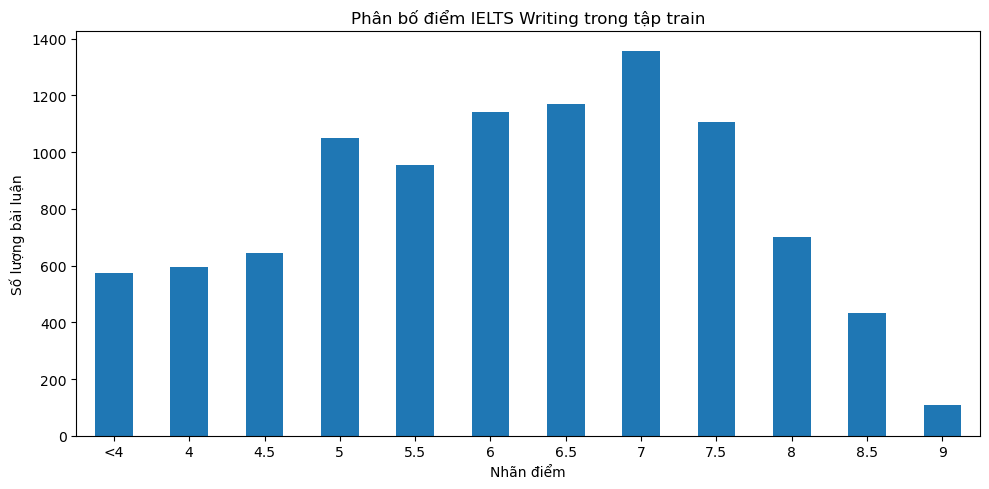

In [40]:
#Khám phá phân bố điểm trong tập train
import matplotlib.pyplot as plt

band_counts = train["band_clean"].value_counts()

# Sắp xếp nhãn theo thứ tự điểm
band_order = ["<4", "4", "4.5", "5", "5.5",
              "6", "6.5", "7", "7.5", "8", "8.5", "9"]

band_counts = band_counts.reindex(band_order, fill_value=0)

print("Bảng phân bố điểm:")
display(band_counts.to_frame("Số lượng"))

plt.figure(figsize=(10, 5))
band_counts.plot(kind="bar")
plt.title("Phân bố điểm IELTS Writing trong tập train")
plt.xlabel("Nhãn điểm")
plt.ylabel("Số lượng bài luận")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.1. Khám phá độ dài bài luận

In [41]:
#Khám phá độ dài bài luận
# Tạo bản sao để phân tích, không sửa dữ liệu gốc
train_eda = train.copy()

# Đếm số từ trong mỗi bài luận
train_eda["word_count"] = (
    train_eda["essay"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("Thống kê độ dài bài luận (số từ):")
display(train_eda["word_count"].describe().to_frame().T)

print("\n5 bài luận ngắn nhất:")
display(
    train_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count")
    .head(5)
)

print("\n5 bài luận dài nhất:")
display(
    train_eda[["essay", "word_count", "band_clean"]]
    .sort_values("word_count", ascending=False)
    .head(5)
)

Thống kê độ dài bài luận (số từ):


,count,mean,std,min,25%,50%,75%,max
word_count,9833.0,292.681989,57.997544,1.0,263.0,289.0,322.0,1557.0



5 bài luận ngắn nhất:


,essay,word_count,band_clean
1579,#NAME?,1,4
5129,"Nowadays,advertising is going to be more and m...",50,<4
1047,"Nowdays, abundant of old age people are experi...",50,<4
1999,"From my perspective, I contend that the increa...",51,<4
8600,"In this twenty-first century, I suggest that t...",51,<4



5 bài luận dài nhất:


,essay,word_count,band_clean
1610,The automotive industry is undergoing one of ...,1557,4.5
2846,Global warming is not a prediction. It is happ...,792,4
1716,"In this contemporary era, every citizen of a c...",678,6
5924,Nobody can deny the growing economic progress ...,591,5
4475,"In this day and age, young people have been st...",578,6.5


## Phần 6. Kiểm tra các mẫu bất thường

In [1]:
import pandas as pd

# Đọc dữ liệu đã chuẩn hóa band
train = pd.read_csv("train_band_normalized.csv")
test = pd.read_csv("test_band_normalized.csv")

# Kiểm tra kích thước dữ liệu
print("Kích thước tập Train:", train.shape)
print("Kích thước tập Test:", test.shape)

# Kiểm tra tên cột và kiểu dữ liệu
print("\nThông tin tập Train:")
train.info()

print("\nThông tin tập Test:")
test.info()

# Hiển thị 5 dòng dữ liệu đầu tiên
display(train.head())


Kích thước tập Train: (9833, 4)
Kích thước tập Test: (491, 4)

Thông tin tập Train:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9833 entries, 0 to 9832
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   prompt      9833 non-null   object
 1   essay       9833 non-null   object
 2   evaluation  9833 non-null   object
 3   band        9833 non-null   object
dtypes: object(4)
memory usage: 307.4+ KB

Thông tin tập Test:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 491 entries, 0 to 490
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   prompt      491 non-null    object
 1   essay       491 non-null    object
 2   evaluation  491 non-null    object
 3   band        491 non-null    object
dtypes: object(4)
memory usage: 15.5+ KB


,prompt,essay,evaluation,band
0,Interviews form the basic criteria for most la...,It is believed by some experts that the tradit...,**Task Achievement: [7]**\nThe essay effective...,7.5
1,Interviews form the basic selecting criteria f...,Nowadays numerous huge firms allocate an inter...,**Task Achievement:** 5.0\n- The candidate has...,5
2,Interview form the basic selection criteria fo...,The interview section is the most vital part o...,## Task Achievement:\n- The candidate has effe...,5.5
3,Interviews form the basic selection criteria f...,It is argued that the best method to recruit e...,## Task Achievement:\n- The candidate has adeq...,5.5
4,Interviews from the basic selecting criteria f...,Nowadays many companies conduct interviews bef...,**Task Achievement:**\n\nThe essay adequately ...,4
